In [3]:
# Parte 1: carga y exploración inicial

# Instalar si hace falta
#if (!require(faraway)) install.packages("faraway")
library(faraway)

# Cargar datos
data(wcgs)

# Revisar estructura
str(wcgs)

Loading required package: faraway

Warning message in library(package, lib.loc = lib.loc, character.only = TRUE, logical.return = TRUE, :
“there is no package called ‘faraway’”
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘rbibutils’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘lme4’




'data.frame':	3154 obs. of  13 variables:
 $ age    : int  49 42 42 41 59 44 44 40 43 42 ...
 $ height : int  73 70 69 68 70 72 72 71 72 70 ...
 $ weight : int  150 160 160 152 150 204 164 150 190 175 ...
 $ sdp    : int  110 154 110 124 144 150 130 138 146 132 ...
 $ dbp    : int  76 84 78 78 86 90 84 60 76 90 ...
 $ chol   : int  225 177 181 132 255 182 155 140 149 325 ...
 $ behave : Factor w/ 4 levels "A1","A2","B3",..: 2 2 3 4 3 4 4 2 3 2 ...
 $ cigs   : int  25 20 0 20 20 0 0 0 25 0 ...
 $ dibep  : Factor w/ 2 levels "A","B": 1 1 2 2 2 2 2 1 2 1 ...
 $ chd    : Factor w/ 2 levels "no","yes": 1 1 1 1 2 1 1 1 1 1 ...
 $ typechd: Factor w/ 4 levels "angina","infdeath",..: 3 3 3 3 2 3 3 3 3 3 ...
 $ timechd: int  1664 3071 3071 3064 1885 3102 3074 3071 3064 1032 ...
 $ arcus  : Factor w/ 2 levels "absent","present": 1 2 1 1 2 1 1 1 1 2 ...


In [10]:
# Quedarnos solo con las variables de interés
datos <- na.omit(wcgs[, c("chd", "cigs")])

# Resumen descriptivo
summary(datos)

  chd            cigs     
 no :2897   Min.   : 0.0  
 yes: 257   1st Qu.: 0.0  
            Median : 0.0  
            Mean   :11.6  
            3rd Qu.:20.0  
            Max.   :99.0  

In [11]:
# Frecuencias de la respuesta
table(datos$chd)
prop.table(table(datos$chd))

# Resumen de cigs según chd
tapply(datos$cigs, datos$chd, summary)


  no  yes 
2897  257 


        no        yes 
0.91851617 0.08148383 

$no
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    0.00    0.00   11.15   20.00   99.00 

$yes
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    0.00   20.00   16.67   30.00   60.00 


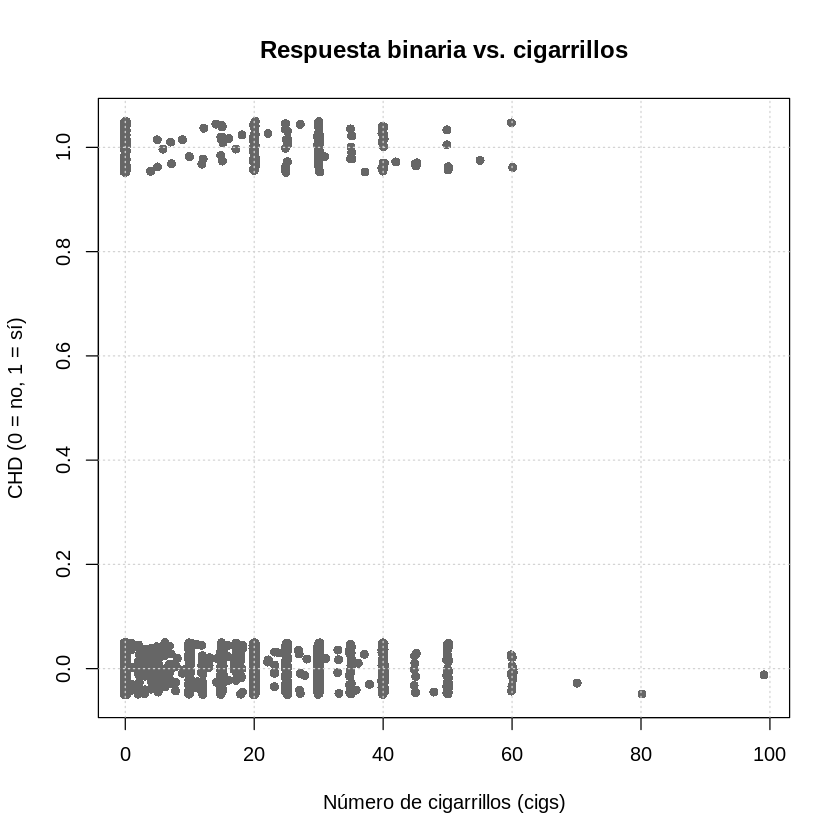

In [12]:
# Parte 2: gráfico exploratorio

chd_num <- as.numeric(datos$chd) - 1
plot(jitter(datos$cigs), jitter(chd_num, amount = 0.05), #Como los datos binarios se montan unos sobre otros, conviene usar jitter
     xlab = "Número de cigarrillos (cigs)",
     ylab = "CHD (0 = no, 1 = sí)",
     main = "Respuesta binaria vs. cigarrillos",
     pch = 16, col = "gray40")
grid()

In [13]:
# Parte 3: ajuste del modelo glm con enlace logit

mod_logit <- glm(chd ~ cigs, data = datos, family = binomial(link = "logit"))

summary(mod_logit)


Call:
glm(formula = chd ~ cigs, family = binomial(link = "logit"), 
    data = datos)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) -2.742160   0.092111 -29.770  < 2e-16 ***
cigs         0.023220   0.004042   5.744 9.22e-09 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 1781.2  on 3153  degrees of freedom
Residual deviance: 1750.0  on 3152  degrees of freedom
AIC: 1754

Number of Fisher Scoring iterations: 5


In [14]:
# Parte 4: interpretación de coeficientes

coef(mod_logit)

# Odds ratios
exp(coef(mod_logit))

# Intervalos de confianza para los odds ratios
exp(confint(mod_logit))

(Intercept)        cigs 
-2.74215950  0.02321981

(Intercept)        cigs 
 0.06443106  1.02349149

Waiting for profiling to be done...



,2.5 %,97.5 %
(Intercept),0.05356251,0.07687144
cigs,1.01535443,1.03159008


In [15]:
# Parte 4: interpretación de los coeficientes

# Coeficientes estimados en escala logit
coeficientes <- coef(mod_logit)
coeficientes

beta0 <- coeficientes["(Intercept)"]
beta1 <- coeficientes["cigs"]

# Exponencial de los coeficientes
odds0 <- exp(beta0)
OR_1  <- exp(beta1)

# Probabilidad estimada cuando cigs = 0
prob0 <- plogis(beta0)

# Cambio porcentual en los odds por cada cigarrillo adicional
cambio_porcentual <- 100 * (OR_1 - 1)

# Odds ratios para aumentos de 5, 10 y 20 cigarrillos diarios
OR_5  <- exp(5 * beta1)
OR_10 <- exp(10 * beta1)
OR_20 <- exp(20 * beta1)

# Mostrar resultados
cat("Intercepto estimado:", round(beta0, 4), "\n")
cat("Pendiente estimada para cigs:", round(beta1, 4), "\n\n")

cat("Odds para una persona que fuma 0 cigarrillos:",
    round(odds0, 4), "\n")

cat("Probabilidad estimada de CHD para una persona que fuma 0 cigarrillos:",
    round(prob0, 4), "\n\n")

cat("Odds ratio por cada cigarrillo adicional:",
    round(OR_1, 4), "\n")

cat("Cambio porcentual en los odds por cada cigarrillo adicional:",
    round(cambio_porcentual, 2), "%\n\n")

cat("Odds ratio por 5 cigarrillos adicionales:",
    round(OR_5, 4), "\n")

cat("Odds ratio por 10 cigarrillos adicionales:",
    round(OR_10, 4), "\n")

cat("Odds ratio por 20 cigarrillos adicionales:",
    round(OR_20, 4), "\n")

(Intercept)        cigs 
-2.74215950  0.02321981

Intercepto estimado: -2.7422 
Pendiente estimada para cigs: 0.0232 

Odds para una persona que fuma 0 cigarrillos: 0.0644 
Probabilidad estimada de CHD para una persona que fuma 0 cigarrillos: 0.0605 

Odds ratio por cada cigarrillo adicional: 1.0235 
Cambio porcentual en los odds por cada cigarrillo adicional: 2.35 %

Odds ratio por 5 cigarrillos adicionales: 1.1231 
Odds ratio por 10 cigarrillos adicionales: 1.2614 
Odds ratio por 20 cigarrillos adicionales: 1.5911 


In [16]:
# Intervalos de confianza de los coeficientes
IC_beta <- confint(mod_logit)

# Intervalos de confianza en escala de odds ratios
IC_OR <- exp(IC_beta)

IC_OR

Waiting for profiling to be done...



,2.5 %,97.5 %
(Intercept),0.05356251,0.07687144
cigs,1.01535443,1.03159008


In [17]:
resultado_cigs <- c(
  Coeficiente = beta1,
  Odds_ratio = exp(beta1),
  IC_95_inferior = exp(IC_beta["cigs", 1]),
  IC_95_superior = exp(IC_beta["cigs", 2])
)

round(resultado_cigs, 4)

Coeficiente.cigs  Odds_ratio.cigs   IC_95_inferior   IC_95_superior 
          0.0232           1.0235           1.0154           1.0316

In [18]:
# Parte 6. Resumen de los Resultados

tabla_interpretacion <- data.frame(
  Cantidad = c(
    "Intercepto",
    "Efecto de 1 cigarrillo",
    "Efecto de 5 cigarrillos",
    "Efecto de 10 cigarrillos",
    "Efecto de 20 cigarrillos"
  ),
  Valor = c(
    exp(beta0),
    exp(beta1),
    exp(5 * beta1),
    exp(10 * beta1),
    exp(20 * beta1)
  ),
  Interpretacion = c(
    "Odds estimados de CHD cuando cigs = 0",
    "Factor multiplicativo de los odds por 1 cigarrillo adicional",
    "Factor multiplicativo de los odds por 5 cigarrillos adicionales",
    "Factor multiplicativo de los odds por 10 cigarrillos adicionales",
    "Factor multiplicativo de los odds por 20 cigarrillos adicionales"
  )
)

tabla_interpretacion$Valor <- round(tabla_interpretacion$Valor, 4)

knitr::kable(
  tabla_interpretacion,
  caption = "Interpretación contextual de los coeficientes del modelo logístico"
)



Table: Interpretación contextual de los coeficientes del modelo logístico

|Cantidad                 |  Valor|Interpretacion                                                   |
|:------------------------|------:|:----------------------------------------------------------------|
|Intercepto               | 0.0644|Odds estimados de CHD cuando cigs = 0                            |
|Efecto de 1 cigarrillo   | 1.0235|Factor multiplicativo de los odds por 1 cigarrillo adicional     |
|Efecto de 5 cigarrillos  | 1.1231|Factor multiplicativo de los odds por 5 cigarrillos adicionales  |
|Efecto de 10 cigarrillos | 1.2614|Factor multiplicativo de los odds por 10 cigarrillos adicionales |
|Efecto de 20 cigarrillos | 1.5911|Factor multiplicativo de los odds por 20 cigarrillos adicionales |

In [19]:
#Parte 7. Probabilidades estimadas
consumo <- data.frame(
  cigs = c(0, 5, 10, 20, 30, 40)
)

consumo$probabilidad_CHD <- predict(
  mod_logit,
  newdata = consumo,
  type = "response"
)

consumo$probabilidad_CHD <- round(
  consumo$probabilidad_CHD,
  4
)

knitr::kable(
  consumo,
  col.names = c(
    "Cigarrillos diarios",
    "Probabilidad estimada de CHD"
  ),
  caption = "Probabilidad estimada de enfermedad coronaria según consumo diario"
)



Table: Probabilidad estimada de enfermedad coronaria según consumo diario

| Cigarrillos diarios| Probabilidad estimada de CHD|
|-------------------:|----------------------------:|
|                   0|                       0.0605|
|                   5|                       0.0675|
|                  10|                       0.0752|
|                  20|                       0.0930|
|                  30|                       0.1145|
|                  40|                       0.1402|

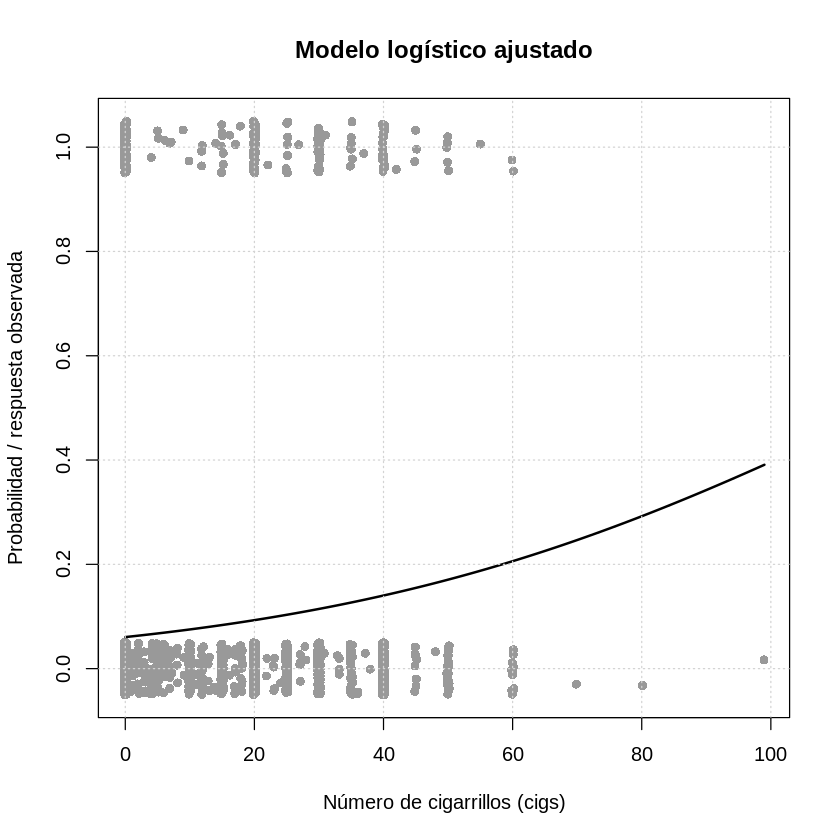

In [20]:
# Parte 8: curva logística ajustada

xg <- seq(min(datos$cigs), max(datos$cigs), length.out = 200)
pg <- predict(mod_logit,
              newdata = data.frame(cigs = xg),
              type = "response")

plot(jitter(datos$cigs), jitter(chd_num, amount = 0.05),
     xlab = "Número de cigarrillos (cigs)",
     ylab = "Probabilidad / respuesta observada",
     main = "Modelo logístico ajustado",
     pch = 16, col = "gray60")

lines(xg, pg, lwd = 2)
grid()

In [21]:
# Parte 9: Clasificación mediante regresión logística

set.seed(123)

# División de los datos: 70% entrenamiento y 30% prueba
indice_train <- sample(
  seq_len(nrow(datos)),
  size = floor(0.70 * nrow(datos))
)

datos_train <- datos[indice_train, ]
datos_test  <- datos[-indice_train, ]

In [22]:
# Ajuste del modelo con los datos de entrenamiento
mod_logit_clas <- glm(
  chd ~ cigs,
  data = datos_train,
  family = binomial(link = "logit")
)

In [24]:
# Probabilidades estimadas para los datos de prueba
prob_test <- predict(
  mod_logit_clas,
  newdata = datos_test,
  type = "response"
)

In [25]:
# Clasificación utilizando un punto de corte de 0.5
umbral <- 0.5
clase_predicha <- ifelse(prob_test >= umbral, 1, 0)

# Clases reales
clase_real <- if (is.factor(datos_test$chd)) {
  as.numeric(datos_test$chd) - 1
} else {
  datos_test$chd
}

# Matriz de confusión
matriz_confusion <- table(
  Real = factor(clase_real, levels = c(0, 1)),
  Predicha = factor(clase_predicha, levels = c(0, 1))
)

matriz_confusion

# Medidas de clasificación
VN <- matriz_confusion["0", "0"]
FP <- matriz_confusion["0", "1"]
FN <- matriz_confusion["1", "0"]
VP <- matriz_confusion["1", "1"]

metricas <- c(
  Exactitud = (VP + VN) / sum(matriz_confusion),
  Sensibilidad = VP / (VP + FN),
  Especificidad = VN / (VN + FP)
)

round(metricas, 3)

    Predicha
Real   0   1
   0 881   0
   1  66   0

Exactitud  Sensibilidad Especificidad 
         0.93          0.00          1.00

In [26]:
summary(prob_test)
max(prob_test)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.06334 0.06334 0.06334 0.08728 0.09945 0.27349 

[1] 0.2734932

In [27]:
sum(prob_test >= 0.50)
sum(prob_test >= 0.20)
sum(prob_test >= 0.10)
sum(prob_test >= 0.05)

[1] 0

[1] 6

[1] 220

[1] 947

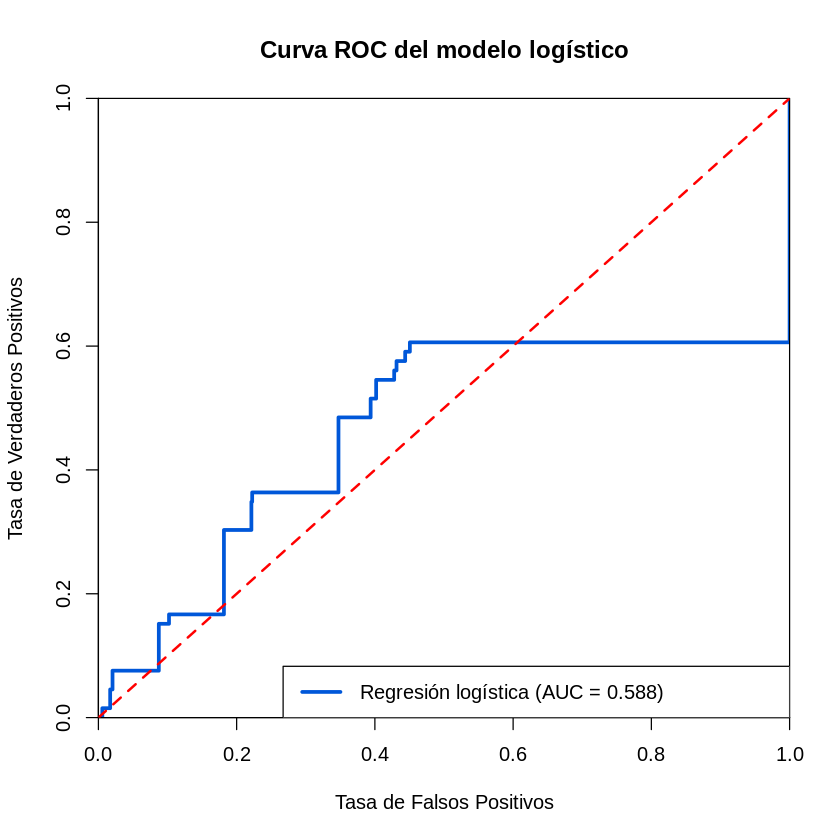

In [29]:
#install.packages("pROC")
library(pROC)

# Construcción de la curva ROC
curva_roc <- roc(
  response = clase_real,
  predictor = prob_test,
  levels = c(0, 1),
  direction = "<"
)

# Coordenadas de la curva
falsos_positivos <- 1 - curva_roc$specificities
verdaderos_positivos <- curva_roc$sensitivities

# Ordenar las coordenadas
orden <- order(
  falsos_positivos,
  verdaderos_positivos
)

# Área bajo la curva
valor_auc <- as.numeric(auc(curva_roc))

# Gráfico
plot(
  falsos_positivos[orden],
  verdaderos_positivos[orden],
  type = "s",
  xlim = c(0, 1),
  ylim = c(0, 1),
  xaxs = "i",
  yaxs = "i",
  col = "#0057D9",
  lwd = 3,
  main = "Curva ROC del modelo logístico",
  xlab = "Tasa de Falsos Positivos",
  ylab = "Tasa de Verdaderos Positivos"
)

# Línea correspondiente a un clasificador al azar
abline(
  a = 0,
  b = 1,
  col = "red",
  lty = 2,
  lwd = 2
)

# Leyenda con el AUC
legend(
  "bottomright",
  legend = sprintf(
    "Regresión logística (AUC = %.3f)",
    valor_auc
  ),
  col = "#0057D9",
  lwd = 3,
  bg = "white"
)

In [30]:
# Punto de corte óptimo según el índice de Youden

punto_optimo <- coords(
  curva_roc,
  x = "best",
  best.method = "youden",
  ret = c("threshold", "sensitivity", "specificity"),
  transpose = FALSE
)

punto_optimo

threshold,sensitivity,specificity
<dbl>,<dbl>,<dbl>
0.06863037,0.6060606,0.5493757


In [31]:
# Clasificación con el punto de corte óptimo

umbral_optimo <- as.numeric(punto_optimo["threshold"])

clase_predicha_optima <- ifelse(
  prob_test >= umbral_optimo,
  1,
  0
)

table(
  Real = factor(clase_real, levels = c(0, 1)),
  Predicha = factor(clase_predicha_optima, levels = c(0, 1))
)

    Predicha
Real   0   1
   0 484 397
   1  26  40